In [5]:
import torch
import torchao
from torch import nn

from tqdm.notebook import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import clear_output

import torchvision
import torch.nn.functional as F

import gc
from collections import defaultdict
import typing as tp
import numpy as np
from scipy.optimize import linprog
import copy
import pickle
from math import sqrt
from copy import deepcopy
from typing import Dict, Iterable, Optional, Union, Any, Callable, Tuple


In [2]:
mnist_transform=torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize((0.1307,), (0.3081,))
])


In [3]:
dataset_train = torchvision.datasets.MNIST('../../datasets/mnist', train=True, download=True, transform=mnist_transform)
dataset_test = torchvision.datasets.MNIST('../../datasets/mnist', train=False, transform=mnist_transform)


In [4]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, 1)
        self.conv2 = nn.Conv2d(32, 64, 3, 1)
        self.conv3 = nn.Conv2d(64, 64, 3, 1)
        # self.dropout1 = nn.Dropout(0.25)
        # self.dropout2 = nn.Dropout(0.5)
        self.fc1 = nn.Linear(6400, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = self.conv2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2)
        #
        x = F.relu(self.conv3(x))
        #
        x = torch.flatten(x, 1)
        x = self.fc1(x)
        x = F.relu(x)
        # x = self.dropout2(x)
        x = self.fc2(x)
        output = F.log_softmax(x, dim=1)
        return output

In [7]:
def get_list_grad_params(net: nn.Module) -> tp.List[torch.Tensor]:
    return [param.grad.detach().cpu() for param in net.parameters() if param.grad is not None]

def calc_grad_info(net: nn.Module, info: tp.List[torch.Tensor]):
    new_grads = get_list_grad_params(net)
    if not info:
        return new_grads
    return [new_grad + cur_grad for new_grad, cur_grad in zip(new_grads, info)]

def get_dif(grad_info_1: tp.List[torch.Tensor], grad_info_2: tp.List[torch.Tensor]) -> tp.List[torch.Tensor]:
    return [grad_1 - grad_2 for grad_1, grad_2 in zip(grad_info_1, grad_info_2)]

def mult_grad(info: tp.List[torch.Tensor], mult: float):
    return [grad * mult for grad in info] 

def get_grad_norm(grads: tp.List[torch.Tensor]):
    return np.sqrt(sum(grad.norm().item() ** 2 for grad in grads))


In [12]:
def plot_loss(values: defaultdict, suptitle: str, filename: str = '__file.pt'):
    clear_output()
    with sns.plotting_context("notebook"), sns.axes_style("darkgrid"):
        plt.figure(figsize=(28, 6), dpi=120)

        subplots_shape = (1, 3)

        plt.suptitle(suptitle)

        plt.subplot(*subplots_shape, 1)
        train_loss = values["train_loss"]
        plt.plot(range(1, len(train_loss) + 1), train_loss)
        plt.title('Train loss')
        plt.xlabel("Iterations")

        plt.subplot(*subplots_shape, 2)
        test_accuracy = values["test_accuracy"]
        plt.plot(range(1, len(test_accuracy) + 1), test_accuracy)
        plt.title('Test accuracy')
        plt.yticks(fontsize=10)
        plt.xlabel("Epochs")

        # plt.subplot(*subplots_shape, 3)
        # error = values["alpha_16/32"]
        # plt.plot(range(1, len(error) + 1), error)
        # plt.title(r'$\alpha$ - relative noise coefficient fp32 $\to$ fp16')
        # plt.xlabel("Iterations")
        
        plt.subplot(*subplots_shape, 3)
        error = values["alpha_16/64"]
        plt.plot(range(1, len(error) + 1), error)
        plt.title(r'$\alpha$ - relative noise coefficient fp64 $\to$ fp16')
        plt.xlabel("Iterations")

        # plt.subplot(*subplots_shape, 5)
        # error = values["alpha_32/64"]
        # plt.plot(range(1, len(error) + 1), error)
        # plt.title(r'$\alpha$ - relative noise coefficient fp64 $\to$ fp32')
        # plt.xlabel("Iterations")

        if filename is not None:
            plt.savefig(f'./output/{filename}.pdf')

        plt.show()

In [22]:
def train_cycle(
    model,
    optim,
    criterion,
    epochs,
    device,
    train_dataloader,
    test_dataloader,
    output_suptitle,
    output_filename,
    verbose=True,
):
    history = defaultdict(list)

    for _ in range(epochs):
        model.train()

        for x, y in tqdm(train_dataloader):
            full_grad_16 = []
            full_grad_64 = []

            optim.zero_grad()
            model_cp = copy.deepcopy(model).half()
            model_cp.train()
            x = x.to(device).type(torch.float16)
            logits = model_cp(x)
            y_ = y.to(device)
            loss_batch = criterion(logits, y_)
            loss_batch.backward()
            full_grad_16 = calc_grad_info(model_cp, full_grad_16)

            optim.zero_grad()
            x = x.to(device).type(torch.double)
            logits = model(x)
            y_ = y.to(device)
            loss_batch = criterion(logits, y_)
            loss_batch.backward()
            full_grad_64 = calc_grad_info(model, full_grad_64)

            history["alpha_16/64"].append(get_grad_norm(get_dif(full_grad_16, full_grad_64)) / get_grad_norm(full_grad_64))
            #history["alpha_16/32"].append(get_grad_norm(get_dif(full_grad_16, full_grad_32)) / get_grad_norm(full_grad_32))
            #history["alpha_32/64"].append(get_grad_norm(get_dif(full_grad_32, full_grad_64)) / get_grad_norm(full_grad_64))

            optim.step()
            loss_ = loss_batch.detach().item()
            history["train_loss"].append(loss_)
            del x
            del y
            del y_
            if 'cuda' in device:
                torch.cuda.synchronize()
                torch.cuda.empty_cache()
                gc.collect()


        model.eval()
        with torch.no_grad():
            accuracy = 0
            total = 0
            for x, y in test_dataloader:
                data, target = x.to(device).type(torch.double), y
                output = model(data)
                pred = output.argmax(dim=1, keepdim=True).T[0].cpu()
                accuracy += pred.eq(target.view_as(pred)).sum().item()
                total += len(y)
            history["test_accuracy"].append(accuracy / total)

        if verbose:
            plot_loss(history, output_suptitle, output_filename)

    return model, history

In [23]:
device = "cuda:0" if torch.cuda.is_available() else "cpu"

model = Net().to(device).double()

batch_size: int = 1024
workers: int = 12
learning_rate = 1e-3

output_data = {
    "batch_size": batch_size,
    "lr": learning_rate,
    "title_prefix": "Simple CNN, MNIST"
}

suptitle = 'Simple CNN, MNIST, floating point gradient quantization'


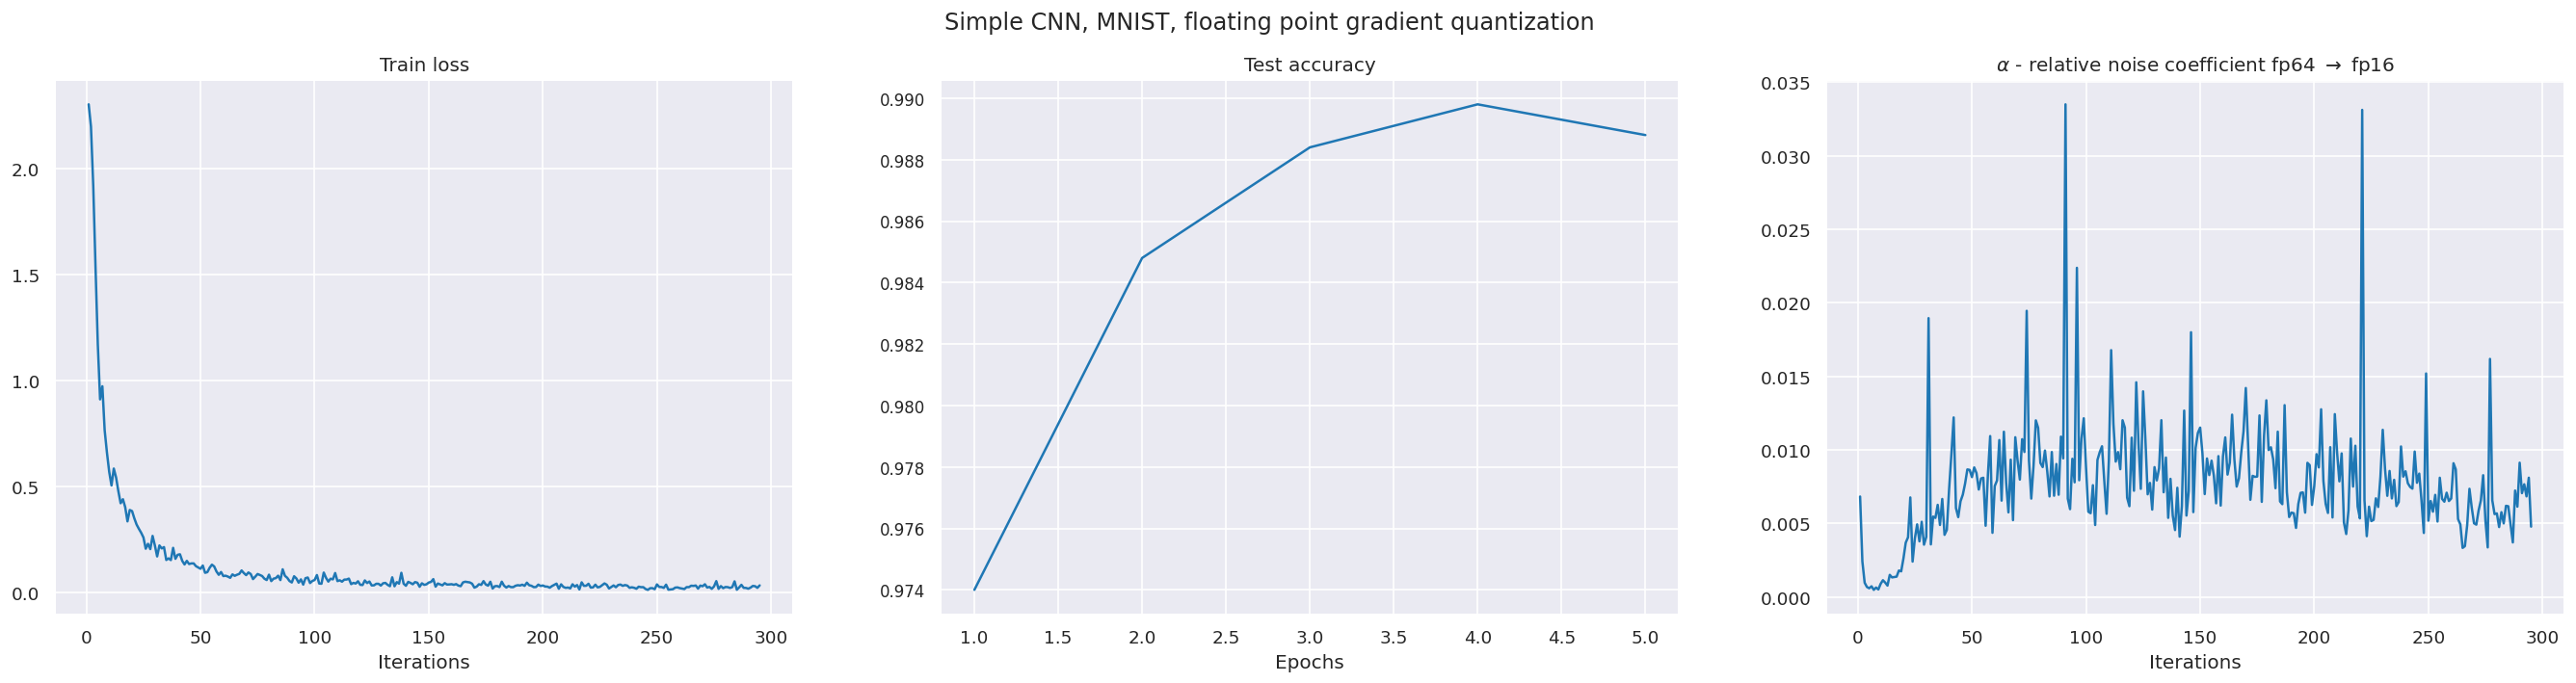

In [ ]:
dataloader_train = torch.utils.data.DataLoader(dataset_train,
                                               num_workers=workers,
                                               batch_size=batch_size,
                                               sampler=torch.utils.data.RandomSampler(dataset_train))

dataloader_test = torch.utils.data.DataLoader(dataset_test,
                                              num_workers=workers,
                                              batch_size=batch_size,
                                              sampler=torch.utils.data.RandomSampler(dataset_test))

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss()
verbose = True

epochs = 5

model, history = train_cycle(model,
                             optimizer,
                             criterion,
                             epochs,
                             device,
                             dataloader_train,
                             dataloader_test,
                             output_suptitle=suptitle,
                             output_filename=None,
                             verbose=True)


In [25]:
with open('./dump_result/mnist_fp.pickle', 'wb') as f:
    pickle.dump(history, f)
